# Chapitre 7 - Cours 3 : PEFT, LoRA et QLoRA

Le cours 2 a montré que la mémoire d'entraînement est dominée par ce que chaque paramètre
**entraînable** traîne avec lui (gradient, états d'Adam). La réponse dominante est le
**finetuning efficace en paramètres** (PEFT, *parameter-efficient finetuning*). Ce notebook
suit la sous-section *Parameter-Efficient Finetuning* de la section *Finetuning
Techniques* : *PEFT techniques*, *LoRA* (*Why does LoRA work?*, *LoRA configurations*,
*Serving LoRA adapters*, *Quantized LoRA*). Au programme :

1. du finetuning complet au finetuning partiel, et le budget de paramètres de chaque
   méthode (calculé sur Qwen2.5-0.5B) ;
2. panorama des techniques PEFT (adaptateurs, LoRA, soft prompts : diagramme) ;
3. LoRA écrite à la main : factorisation de rang faible, rang, $\alpha$, fusion ;
4. pourquoi LoRA fonctionne : la différence entre Qwen2.5-0.5B et sa version Instruct
   est-elle de rang faible ?
5. configurer LoRA : quelles matrices, quel rang (calculs du livre sur GPT-3) ;
6. un **vrai finetuning LoRA** avec `peft` sur la tâche des tickets clients (avant /
   après, courbes de perte, effets de bord) ;
7. servir des adaptateurs LoRA (fusion, multi-LoRA, stockage) ;
8. QLoRA : base en NF4, adaptateurs en BF16, exécuté avec bitsandbytes sur ce GPU.

In [1]:
import os

os.environ.setdefault("HF_HUB_OFFLINE", "1")  # tous les modèles sont déjà en cache local

import gc
import tempfile
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from aie.plotting import (INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, finish)
from aie.diagrams import Diagram
from aie import llm
from aie import ch07_finetuning as c7

warnings.filterwarnings("ignore")
c7.setup_style()
llm.seed_everything(0)
GB = 1e9
pd.set_option("display.max_colwidth", 100)

## 1. Du finetuning complet au finetuning partiel (section *Parameter-Efficient Finetuning*)

Au **finetuning complet**, tous les paramètres sont entraînables. Le livre fait le compte
pour un modèle de 7 B en 16 bits : 14 Go de poids, plus $7 \cdot 10^9 \times 3 \times 2 = 42$ Go
pour gradients et états d'Adam, soit 56 Go sans les activations, alors que les GPU grand
public offrent 12 à 24 Go. Deux familles de parades : réduire l'empreinte (quantification,
PEFT) ou mieux utiliser la mémoire disponible (déchargement vers le CPU, comme DeepSpeed).

Le **finetuning partiel** gèle la plupart des couches et n'entraîne que les dernières
(les plus spécifiques à la tâche). Il réduit la mémoire mais il est **inefficace en
paramètres** : Houlsby et al. (2019) montrent qu'avec BERT il faut mettre à jour environ
25 % des paramètres pour approcher le finetuning complet sur GLUE, alors que leurs
**adaptateurs** y parviennent (à 0,4 % près) avec 3 % des paramètres. Une technique est dite
efficace en paramètres quand elle approche le finetuning complet avec **plusieurs ordres de
grandeur** de paramètres entraînables en moins.

Comptons, pour Qwen2.5-0.5B, le nombre de paramètres entraînables de chaque approche
(formules détaillées dans les sections suivantes).

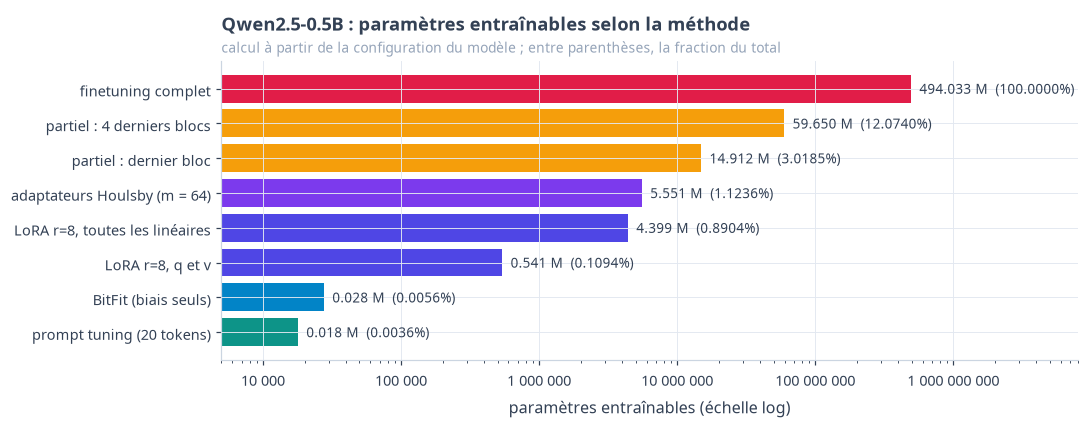

In [2]:
from transformers import AutoConfig

cfg = AutoConfig.from_pretrained(llm.SMALL)
cd = cfg.to_dict()
d_model, L, ff = cfg.hidden_size, cfg.num_hidden_layers, cfg.intermediate_size
shapes = c7.module_shapes(cfg)
block = sum(o * i for o, i in shapes.values()) + 2 * d_model + sum(shapes[k][0] for k in ["q_proj", "k_proj", "v_proj"])
N_total = 494_032_768
budget = {
    "finetuning complet": N_total,
    "partiel : 4 derniers blocs": 4 * block,
    "partiel : dernier bloc": block,
    "adaptateurs Houlsby (m = 64)": L * 2 * (2 * d_model * 64 + d_model + 64),
    "LoRA r=8, toutes les linéaires": c7.lora_params_for_model(cd, list(shapes), 8),
    "LoRA r=8, q et v": c7.lora_params_for_model(cd, ["q_proj", "v_proj"], 8),
    "BitFit (biais seuls)": L * sum(shapes[k][0] for k in ["q_proj", "k_proj", "v_proj"]),
    "prompt tuning (20 tokens)": 20 * d_model,
}
bud = pd.Series(budget)
fig, ax = plt.subplots(figsize=(10, 4))
cols = [ROSE, AMBER, AMBER, VIOLET, INDIGO, INDIGO, SKY, TEAL]
ax.barh(bud.index, bud.values, color=cols)
for i, v in enumerate(bud.values):
    ax.text(v * 1.15, i, f"{v / 1e6:,.3f} M  ({v / N_total:.4%})".replace(",", " "), va="center", fontsize=8.8)
ax.set_xscale("log"); c7.plain_log(ax, "x"); ax.invert_yaxis(); ax.set_xlim(5e3, 8e9)
ax.set_xlabel("paramètres entraînables (échelle log)")
c7.title_sub(ax, "Qwen2.5-0.5B : paramètres entraînables selon la méthode",
             "calcul à partir de la configuration du modèle ; entre parenthèses, la fraction du total")
plt.tight_layout(); plt.show()

Cinq ordres de grandeur séparent le finetuning complet du prompt tuning. Et comme la
mémoire d'entraînement « en plus des poids » est proportionnelle à ces nombres (cours 2),
PEFT rend le finetuning accessible sur du matériel modeste. Le livre souligne un second
avantage : les méthodes PEFT sont aussi **efficaces en échantillons** (quelques milliers
d'exemples, parfois moins, contre des dizaines de milliers pour le finetuning complet).

> **À retenir.** Finetuning partiel : moins de mémoire, mais beaucoup de paramètres pour
> une bonne qualité. PEFT : qualité proche du finetuning complet avec des ordres de
> grandeur de paramètres entraînables en moins.

## 2. Panorama des techniques PEFT (section *PEFT techniques*)

Le livre range les méthodes PEFT en deux familles :

- les méthodes **à adaptateurs** (ou *additives*) ajoutent des modules entraînables au
  modèle gelé : adaptateurs de Houlsby, **LoRA** (de loin la plus utilisée), BitFit, IA3,
  LongLoRA ;
- les méthodes à **soft prompts** ajoutent des « tokens » entraînables à l'entrée : des
  vecteurs continus, illisibles, optimisés par rétropropagation, contrairement aux
  prompts « durs » faits de vrais tokens. Prefix-tuning, P-Tuning et prompt tuning
  diffèrent surtout par **l'endroit** où ces vecteurs sont insérés (à chaque couche ou
  seulement à l'entrée). L'auteure avoue n'avoir jamais rencontré quelqu'un capable
  d'expliquer leurs différences au pied levé.

Les adaptateurs de Houlsby, insérés **en série** dans chaque bloc, ajoutent de la latence
à l'inférence. LoRA les place **en parallèle** d'une matrice existante, et peut ensuite
être fusionnée dans cette matrice : aucune latence supplémentaire.

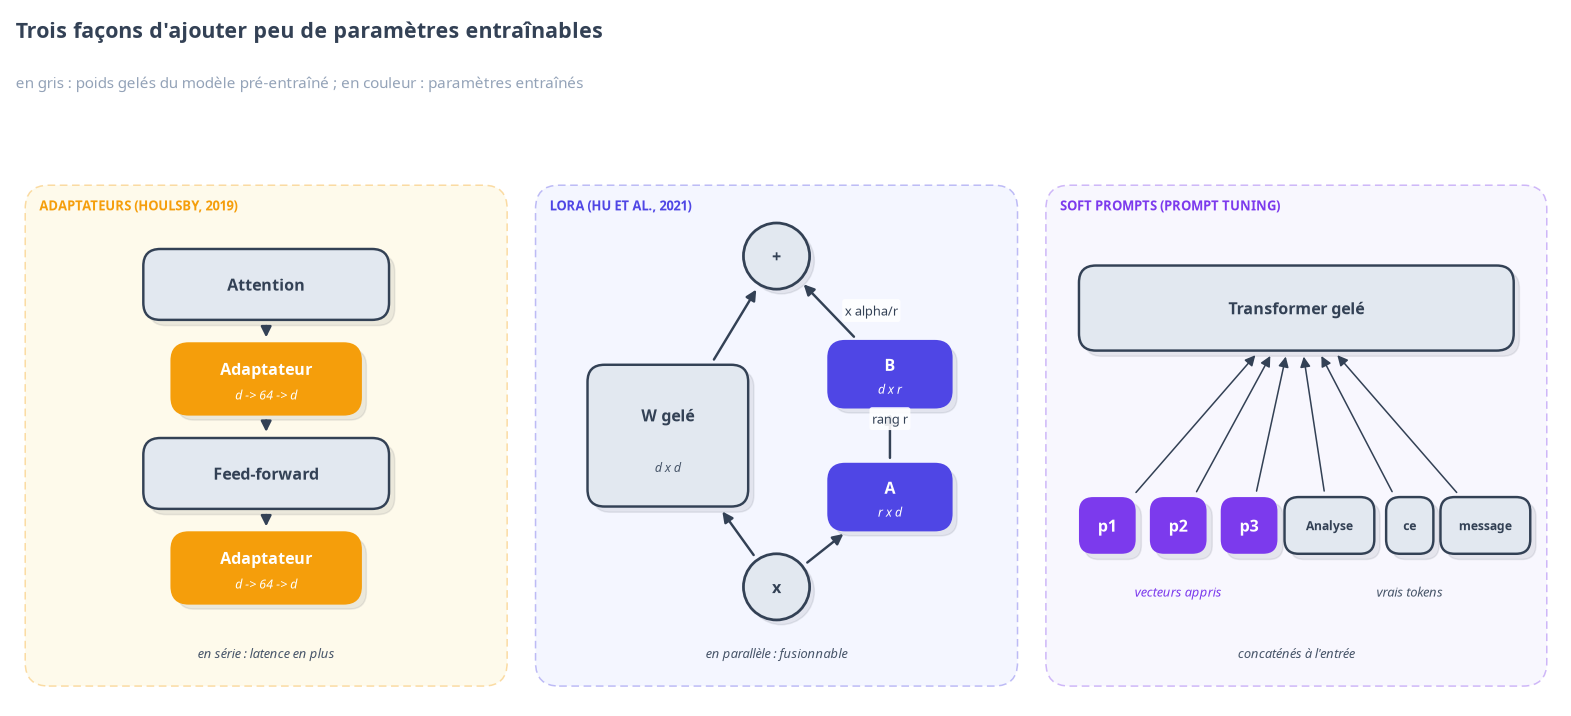

In [3]:
d = Diagram(16.4, 6.4, title="Trois façons d'ajouter peu de paramètres entraînables",
            subtitle="en gris : poids gelés du modèle pré-entraîné ; en couleur : paramètres entraînés")
d.group(0.15, 0.2, 5.25, 5.5, "adaptateurs (Houlsby, 2019)", AMBER)
d.box("att", 2.7, 4.45, "Attention", color=SLATE, w=2.6, h=0.75)
d.box("ad1", 2.7, 3.45, "Adaptateur", sub="d -> 64 -> d", color=AMBER, w=2.0, h=0.75, filled=True)
d.box("ffn", 2.7, 2.45, "Feed-forward", color=SLATE, w=2.6, h=0.75)
d.box("ad2", 2.7, 1.45, "Adaptateur", sub="d -> 64 -> d", color=AMBER, w=2.0, h=0.75, filled=True)
d.arrow("att", "ad1"); d.arrow("ad1", "ffn"); d.arrow("ffn", "ad2")
d.note(2.7, 0.55, "en série : latence en plus", fontsize=8.5)

d.group(5.55, 0.2, 10.65, 5.5, "LoRA (Hu et al., 2021)", INDIGO)
d.box("x", 8.1, 1.25, "x", color=SLATE, kind="circle", w=0.7)
d.box("W", 6.95, 2.85, "W gelé", sub="d x d", color=SLATE, w=1.7, h=1.5)
d.box("A", 9.3, 2.2, "A", sub="r x d", color=INDIGO, w=1.3, h=0.7, filled=True)
d.box("B", 9.3, 3.5, "B", sub="d x r", color=INDIGO, w=1.3, h=0.7, filled=True)
d.box("h", 8.1, 4.75, "+", color=SLATE, kind="circle", w=0.7)
d.arrow("x", "W"); d.arrow("x", "A"); d.arrow("A", "B", "rang r"); d.arrow("W", "h"); d.arrow("B", "h", "x alpha/r", label_offset=(0.45, 0))
d.note(8.1, 0.55, "en parallèle : fusionnable", fontsize=8.5)

d.group(10.95, 0.2, 16.25, 5.5, "soft prompts (prompt tuning)", VIOLET)
d.box("tr", 13.6, 4.2, "Transformer gelé", color=SLATE, w=4.6, h=0.9)
for i, (nm, txt) in enumerate([("p1", "p1"), ("p2", "p2"), ("p3", "p3")]):
    d.box(nm, 11.6 + i * 0.75, 1.9, txt, color=VIOLET, kind="tag", w=0.6, h=0.6)
for nm, txt, xx, ww in [("t1", "Analyse", 13.95, 0.95), ("t2", "ce", 14.8, 0.5), ("t3", "message", 15.6, 0.95)]:
    d.box(nm, xx, 1.9, txt, color=SLATE, w=ww, h=0.6, fontsize=8)
for nm in ["p1", "p2", "p3", "t1", "t2", "t3"]:
    d.arrow(nm, "tr", lw=1.0)
d.note(12.35, 1.2, "vecteurs appris", color=VIOLET, fontsize=8.5)
d.note(14.8, 1.2, "vrais tokens", fontsize=8.5)
d.note(13.6, 0.55, "concaténés à l'entrée", fontsize=8.5)
d.show()

Le livre a mesuré la popularité des techniques en comptant les issues GitHub du dépôt
`huggingface/peft` (octobre 2024) : LoRA domine nettement ; les soft prompts restent
minoritaires, mais intéressent ceux qui veulent plus de contrôle que le prompt sans
investir dans un vrai finetuning. Les frameworks (PEFT, Axolotl, unsloth, LitGPT) les
implémentent tous ; nous utiliserons `peft` en section 6.

> **À retenir.** Adaptateurs = modules ajoutés au modèle gelé (LoRA en tête) ; soft
> prompts = vecteurs d'entrée entraînables. LoRA s'est imposée car elle ne coûte rien à
> l'inférence une fois fusionnée.

## 3. LoRA écrite à la main (section *LoRA*)

**Factorisation de rang faible.** Une matrice $n \times m$ de rang $r$ s'écrit comme le
produit d'une matrice $n \times r$ et d'une matrice $r \times m$ : $r(n+m)$ nombres au lieu
de $nm$. L'exemple du livre : une matrice $9 \times 9$ (81 nombres) de rang 1 se stocke
avec $9 + 9 = 18$ nombres. Pour une matrice quelconque, la meilleure approximation de
rang $r$ (au sens de Frobenius) est donnée par la **SVD tronquée** (théorème
d'Eckart-Young), et l'erreur décroît avec $r$.

**LoRA.** Plutôt que de factoriser $W$ elle-même, LoRA factorise la **mise à jour** : pour
une matrice $W \in \mathbb R^{d_{out} \times d_{in}}$ gelée,
$$W' = W + \frac{\alpha}{r}\, B A, \qquad A \in \mathbb R^{r \times d_{in}},\; B \in \mathbb R^{d_{out} \times r}.$$
Seuls $A$ et $B$ sont entraînés : $r(d_{in} + d_{out})$ paramètres. Le livre note le
produit $W_A W_B$ avec des conventions de dimensions transposées ; le principe est le même.
Deux détails d'implémentation (article de Hu et al.) :

- $B$ est initialisée à **zéro** et $A$ aléatoirement : au départ $BA = 0$, le modèle
  adapté est **exactement** le modèle de base ;
- le facteur $\alpha/r$ découple l'amplitude de la mise à jour du rang : changer $r$
  n'oblige pas à réajuster le taux d'apprentissage.

Notre implémentation (`c7.make_lora_linear_class`) tient en vingt lignes. Vérifions ses
propriétés sur une couche de taille réelle (896 x 896, comme `q_proj` de Qwen2.5-0.5B).

In [4]:
LoRALinear = c7.make_lora_linear_class()
torch.manual_seed(0)
base = torch.nn.Linear(896, 896, bias=False)
lay = LoRALinear(base, r=8, alpha=16)
xb = torch.randn(4, 896)
same_at_init = torch.allclose(lay(xb), base(xb))
with torch.no_grad():
    lay.B.normal_(0, 0.02)
merged = lay.merged()
n_lora = sum(p.numel() for p in lay.parameters() if p.requires_grad)
pd.DataFrame({"valeur": [str(same_at_init), f"{(merged(xb) - lay(xb)).abs().max().item():.2e}",
                         f"{896 * 896:,}".replace(",", " "), f"{n_lora:,}".replace(",", " "),
                         f"{n_lora / 896 ** 2:.2%}", str(torch.linalg.matrix_rank(lay.delta_weight()).item())]},
             index=["sortie identique au modèle de base à l'initialisation", "écart max couche fusionnée / non fusionnée",
                    "paramètres de W (gelés)", "paramètres LoRA (A et B)", "fraction entraînable", "rang de la mise à jour BA"])

,valeur
sortie identique au modèle de base à l'initialisation,True
écart max couche fusionnée / non fusionnée,1.03e-06
paramètres de W (gelés),802 816
paramètres LoRA (A et B),14 336
fraction entraînable,1.79%
rang de la mise à jour BA,8


**Expérience : apprendre une mise à jour de rang faible.** On fabrique une « tâche » dont
la solution est $W^\star = W_0 + \Delta$, avec $\Delta$ de rang 4 (plus un léger bruit de
rang plein), et l'on entraîne une LoRA de rang $r$ à partir de $W_0$, sur des paires
$(x, W^\star x)$. Si le rang de la LoRA atteint celui de la mise à jour, l'erreur doit
s'effondrer.

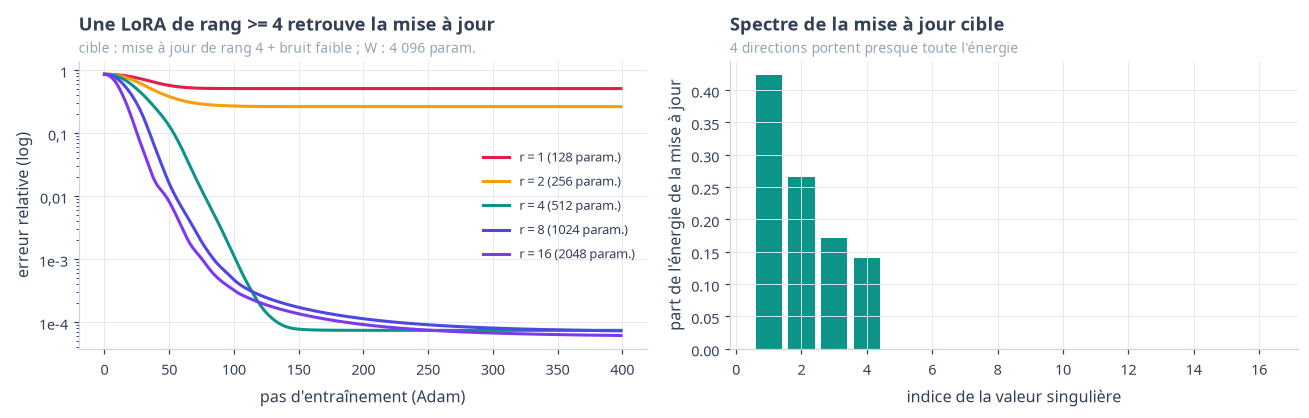

In [5]:
rng = np.random.default_rng(0)
dim = 64
W0 = rng.normal(0, 1 / np.sqrt(dim), (dim, dim))
Delta = rng.normal(size=(dim, 4)) @ rng.normal(size=(4, dim)) * 0.15 + rng.normal(0, 0.003, (dim, dim))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
final = {}
for r, col in zip([1, 2, 4, 8, 16], [ROSE, AMBER, TEAL, INDIGO, VIOLET]):
    h_ = c7.train_lora_toy(W0, W0 + Delta, r=r, steps=400, lr=1e-2)
    final[r] = h_[-1]
    axes[0].plot(h_, color=col, label=f"r = {r} ({c7.lora_param_count(dim, dim, r)} param.)")
axes[0].set_yscale("log"); c7.sci_log(axes[0], "y"); axes[0].set_xlabel("pas d'entraînement (Adam)"); axes[0].set_ylabel("erreur relative (log)")
axes[0].legend(fontsize=8.5)
c7.title_sub(axes[0], "Une LoRA de rang >= 4 retrouve la mise à jour", "cible : mise à jour de rang 4 + bruit faible ; W : 4 096 param.")
S = np.linalg.svd(Delta, compute_uv=False)
axes[1].bar(np.arange(1, 17), (S ** 2 / (S ** 2).sum())[:16], color=[TEAL if i < 4 else GRAY for i in range(16)])
axes[1].set_xlabel("indice de la valeur singulière"); axes[1].set_ylabel("part de l'énergie de la mise à jour")
c7.title_sub(axes[1], "Spectre de la mise à jour cible", "4 directions portent presque toute l'énergie")
plt.tight_layout(); plt.show()

Avec $r < 4$, la LoRA ne peut capturer qu'une partie des directions de la mise à jour :
l'erreur plafonne. Dès $r = 4$, elle tombe au niveau du bruit ; monter à 8 ou 16
n'apporte plus rien, sinon des paramètres. C'est l'observation du livre : au-delà d'un
certain rang, augmenter $r$ n'améliore pas la qualité.

**Le rôle de $\alpha$.** À rang fixé, $\alpha/r$ multiplie la mise à jour, donc agit comme
un multiplicateur du taux d'apprentissage effectif sur $BA$. Le livre rapporte des ratios
$\alpha : r$ usuels entre 1:8 et 8:1.

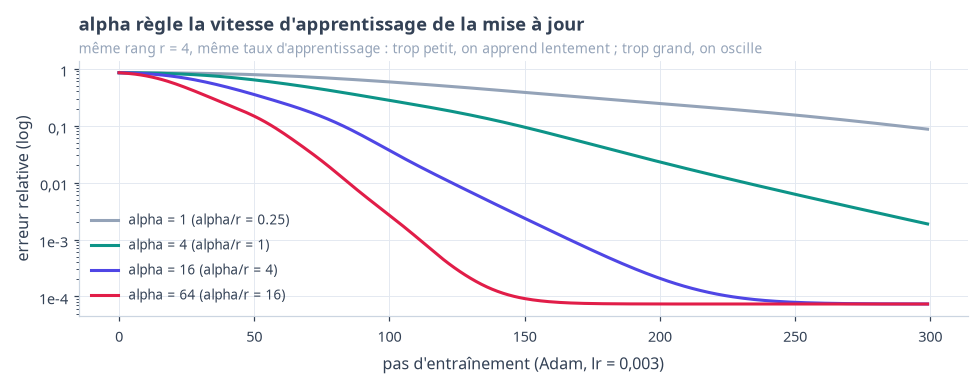

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for alpha, col in zip([1, 4, 16, 64], [GRAY, TEAL, INDIGO, ROSE]):
    h_ = c7.train_lora_toy(W0, W0 + Delta, r=4, alpha=alpha, steps=300, lr=3e-3)
    ax.plot(h_, color=col, label=f"alpha = {alpha} (alpha/r = {alpha / 4:g})")
ax.set_yscale("log"); c7.sci_log(ax, "y"); ax.set_xlabel("pas d'entraînement (Adam, lr = 0,003)"); ax.set_ylabel("erreur relative (log)")
ax.legend(fontsize=8.8)
c7.title_sub(ax, "alpha règle la vitesse d'apprentissage de la mise à jour",
             "même rang r = 4, même taux d'apprentissage : trop petit, on apprend lentement ; trop grand, on oscille")
plt.tight_layout(); plt.show()

> **À retenir.** LoRA : $W' = W + \frac{\alpha}{r} BA$ avec $B = 0$ au départ ;
> $r(d_{in} + d_{out})$ paramètres par matrice. Le rang doit suffire à la complexité de la
> mise à jour ; $\alpha$ en règle l'amplitude. Une fois $BA$ ajouté à $W$, la couche est
> une couche ordinaire.

## 4. Pourquoi LoRA fonctionne : la dimension intrinsèque (section *Why does LoRA work?*)

Pourquoi si peu de paramètres suffiraient-ils à changer le comportement d'un modèle de
milliards de paramètres ? Le livre résume l'argument de Li et al. (2018), Aghajanyan et
al. (2020) et Hu et al. (2021) : les LLM, bien qu'énormes, ont une **dimension
intrinsèque** très faible pour les tâches en aval, d'autant plus faible que le modèle est
grand et bien pré-entraîné ; le pré-entraînement agirait comme une **compression**.

**Une vérification sur de vrais poids.** Qwen publie le modèle de base Qwen2.5-0.5B et sa
version post-entraînée Qwen2.5-0.5B-Instruct (SFT + préférence, en finetuning complet).
Si la mise à jour $\Delta W = W_{\text{Instruct}} - W_{\text{base}}$ est « de rang faible »,
l'essentiel de son énergie doit tenir dans quelques valeurs singulières, bien plus vite
que pour $W$ lui-même. On lit directement les tenseurs dans les fichiers `safetensors`
déjà téléchargés (sur CPU).

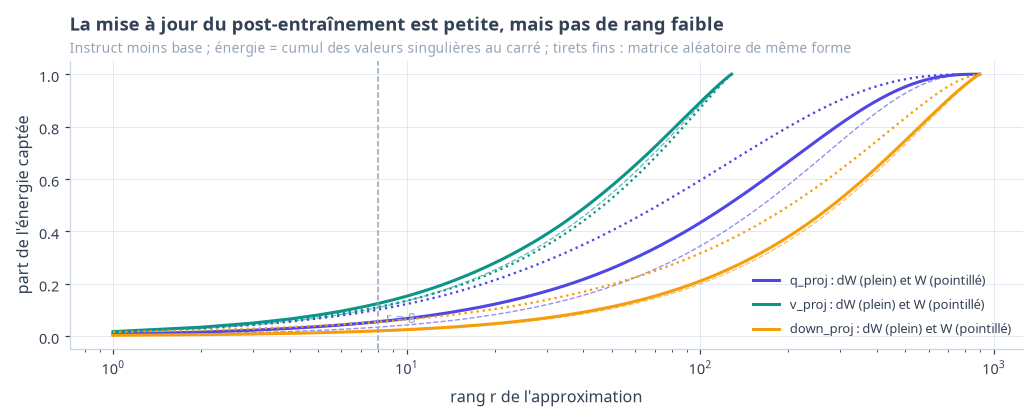

,matrice (couche 12),forme,||dW|| / ||W||,rang pour 50 % de l'énergie de W,rang pour 50 % de l'énergie de dW,énergie de dW dans le rang 8,énergie de dW dans le rang 64,"même chose, matrice aléatoire (rang 8)"
0,q_proj,"(896, 896)",0.088,73,124,0.055,0.313,0.034
1,v_proj,"(128, 896)",0.047,47,42,0.124,0.681,0.109
2,down_proj,"(896, 4864)",0.082,203,283,0.020,0.141,0.018


In [7]:
from huggingface_hub import hf_hub_download
from safetensors import safe_open


def read_tensor(model_id, name):
    path = hf_hub_download(model_id, "model.safetensors", local_files_only=True)
    with safe_open(path, "pt") as f:
        return f.get_tensor(name).float()


rows, spectra = [], {}
for nm in ["model.layers.12.self_attn.q_proj.weight", "model.layers.12.self_attn.v_proj.weight",
           "model.layers.12.mlp.down_proj.weight"]:
    Wb = read_tensor("Qwen/Qwen2.5-0.5B", nm); Wi = read_tensor(llm.SMALL, nm)
    D = Wi - Wb
    s_w = torch.linalg.svdvals(Wb).numpy(); s_d = torch.linalg.svdvals(D).numpy()
    s_r = torch.linalg.svdvals(torch.randn(D.shape, generator=torch.Generator().manual_seed(0))).numpy()
    e_w, e_d = np.cumsum(s_w ** 2) / (s_w ** 2).sum(), np.cumsum(s_d ** 2) / (s_d ** 2).sum()
    e_r = np.cumsum(s_r ** 2) / (s_r ** 2).sum()
    short = nm.split(".")[-2]
    spectra[short] = (e_w, e_d, e_r)
    rows.append({"matrice (couche 12)": short, "forme": tuple(D.shape),
                 "||dW|| / ||W||": (D.norm() / Wb.norm()).item(),
                 "rang pour 50 % de l'énergie de W": int(np.searchsorted(e_w, 0.5)) + 1,
                 "rang pour 50 % de l'énergie de dW": int(np.searchsorted(e_d, 0.5)) + 1,
                 "énergie de dW dans le rang 8": e_d[7], "énergie de dW dans le rang 64": e_d[63],
                 "même chose, matrice aléatoire (rang 8)": e_r[7]})
fig, ax = plt.subplots(figsize=(9.5, 3.9))
for (short, (e_w, e_d, e_r)), col in zip(spectra.items(), [INDIGO, TEAL, AMBER]):
    k = np.arange(1, len(e_w) + 1)
    ax.plot(k, e_w, color=col, ls=":", lw=1.5)
    ax.plot(np.arange(1, len(e_d) + 1), e_d, color=col, label=f"{short} : dW (plein) et W (pointillé)")
    ax.plot(np.arange(1, len(e_r) + 1), e_r, color=col, ls="--", lw=0.9, alpha=0.6)
ax.set_xscale("log"); ax.set_xlabel("rang r de l'approximation"); ax.set_ylabel("part de l'énergie captée")
ax.axvline(8, color=GRAY, lw=1, ls="--"); ax.text(8.5, 0.05, "r = 8", color=GRAY, fontsize=9)
ax.legend(fontsize=8.5, loc="lower right")
c7.title_sub(ax, "La mise à jour du post-entraînement est petite, mais pas de rang faible",
             "Instruct moins base ; énergie = cumul des valeurs singulières au carré ; tirets fins : matrice aléatoire de même forme")
plt.tight_layout(); plt.show()
pd.DataFrame(rows).round(3)

Lecture honnête : la mise à jour du post-entraînement est **petite** devant les poids
(5 à 9 % en norme), mais elle **n'est pas de rang faible** : il faut des centaines de
directions pour capter la moitié de son énergie, parfois davantage que pour $W$ lui-même,
et les 8 premières n'en portent que quelques pour cent. Elle est à peine plus concentrée
qu'une matrice aléatoire. Ce n'est pas une contradiction avec LoRA : un post-entraînement
complet sur des millions d'exemples et de nombreuses tâches n'a aucune raison de produire
une mise à jour de rang faible. L'hypothèse de LoRA est plus modeste : pour **une** tâche
ciblée, il **existe** une mise à jour de rang faible qui obtient l'essentiel du gain, même
si ce n'est pas celle que trouverait un finetuning complet. La section 6 le vérifie en
pratique, et l'exercice 7.9 compare les rangs 1, 4 et 32 sur notre tâche.

Le livre pose aussi la question inverse : pourquoi ne pas **pré-entraîner** en rang
faible ? Des tentatives existent (ReLoRA jusqu'à 1,3 B paramètres, GaLore jusqu'à 7 B),
mais si l'argument de compression est juste, un pré-entraînement de rang plein reste
nécessaire pour faire baisser la dimension intrinsèque à un niveau où le rang faible suffit.

> **À retenir.** LoRA repose sur l'idée qu'adapter un modèle bien pré-entraîné à **une**
> tâche demande peu de « degrés de liberté ». Une mise à jour de finetuning complet,
> elle, est petite mais pas de rang faible : LoRA en cherche une autre, compacte.

## 5. Configurer LoRA (section *LoRA configurations*)

Deux décisions : **à quelles matrices** appliquer LoRA, et **avec quel rang**. LoRA
s'applique matrice par matrice (le plus souvent uniformément à toutes les matrices d'un
même type) ; historiquement aux projections d'attention $W_q, W_k, W_v, W_o$.

**Le calcul du livre sur GPT-3 175B** (96 couches, $d = 12\,288$) : avec un budget de 18 M
paramètres (0,01 % du modèle), on peut s'offrir une matrice en rang 8, deux en rang 4 ou
les quatre en rang 2 : $(12\,288 \times 2 \times 2) \times 4 \times 96 = 18\,874\,368$.
Hu et al. trouvent que les quatre matrices en rang 2 font le mieux (tableau 7-5).

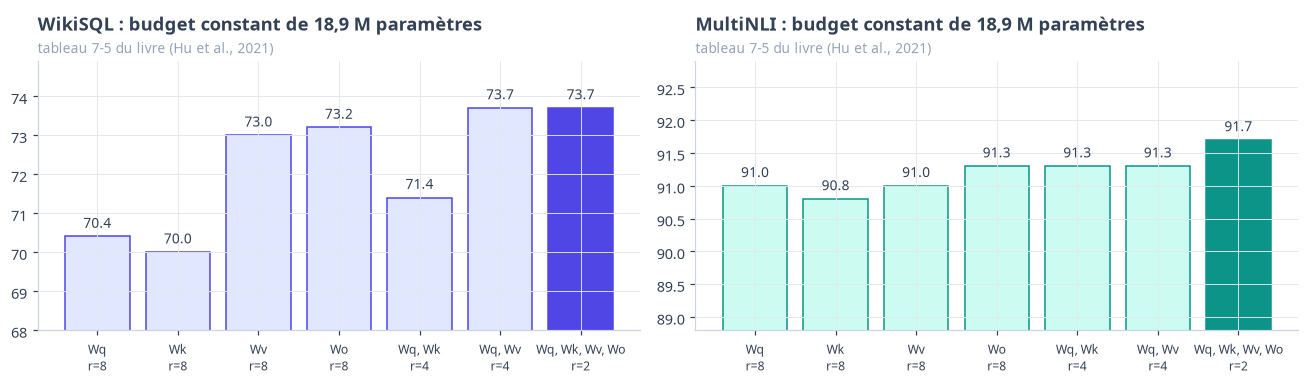

,0,1,2,3,4,5,6
matrices,Wq,Wk,Wv,Wo,"Wq, Wk","Wq, Wv","Wq, Wk, Wv, Wo"
rang,8,8,8,8,4,4,2
paramètres (calculés),18874368,18874368,18874368,18874368,18874368,18874368,18874368


In [8]:
gpt3 = {"hidden_size": 12288, "num_attention_heads": 96, "intermediate_size": 4 * 12288, "num_hidden_layers": 96}
t75 = pd.DataFrame({
    "matrices": ["Wq", "Wk", "Wv", "Wo", "Wq, Wk", "Wq, Wv", "Wq, Wk, Wv, Wo"],
    "rang": [8, 8, 8, 8, 4, 4, 2],
    "WikiSQL": [70.4, 70.0, 73.0, 73.2, 71.4, 73.7, 73.7],
    "MultiNLI": [91.0, 90.8, 91.0, 91.3, 91.3, 91.3, 91.7]})
mp = {"Wq": "q_proj", "Wk": "k_proj", "Wv": "v_proj", "Wo": "o_proj"}
t75["paramètres (calculés)"] = [c7.lora_params_for_model(gpt3, [mp[x.strip()] for x in m_.split(",")], r_)
                                for m_, r_ in zip(t75["matrices"], t75["rang"])]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, col_, c in zip(axes, ["WikiSQL", "MultiNLI"], [INDIGO, TEAL]):
    bars = ax.bar(t75["matrices"] + "\nr=" + t75["rang"].astype(str), t75[col_], color=[LIGHT[c]] * 6 + [c], edgecolor=c)
    annotate_bars(ax, "{:.1f}")
    ax.set_ylim(t75[col_].min() - 2, t75[col_].max() + 1.2); ax.tick_params(axis="x", labelsize=8)
    c7.title_sub(ax, f"{col_} : budget constant de 18,9 M paramètres", "tableau 7-5 du livre (Hu et al., 2021)")
plt.tight_layout(); plt.show()
t75[["matrices", "rang", "paramètres (calculés)"]].T

Notre fonction `c7.lora_params_for_model` retrouve exactement les 18 874 368 paramètres
pour chaque ligne (budget constant). À budget égal, **répartir** un rang faible sur
davantage de matrices vaut mieux que concentrer un rang élevé sur une seule ; à défaut, le
couple $(W_q, W_v)$ est le meilleur choix à deux matrices. Les retours d'expérience cités
(Databricks, Fomenko et al.) ajoutent que LoRA sur les couches **feed-forward** apporte
souvent le plus gros gain. Pour Qwen2.5-0.5B (attention à requêtes groupées : $W_k$ et $W_v$
ne font que $128 \times 896$), voici le nombre de paramètres selon le choix :

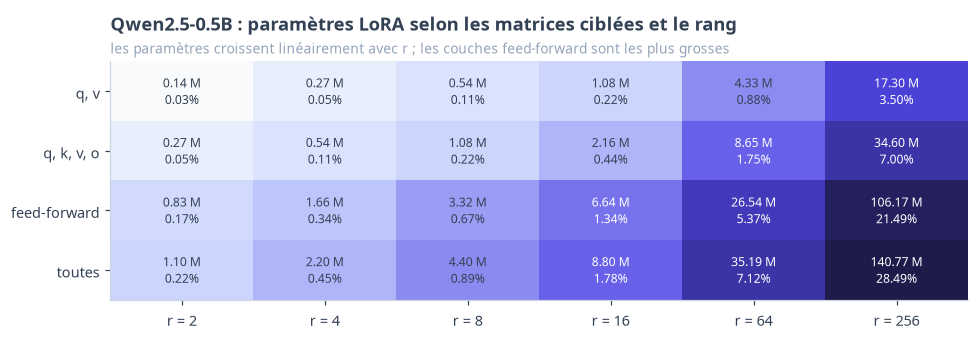

In [9]:
choices = {"q, v": ["q_proj", "v_proj"], "q, k, v, o": ["q_proj", "k_proj", "v_proj", "o_proj"],
           "feed-forward": ["gate_proj", "up_proj", "down_proj"], "toutes": list(shapes)}
ranks = [2, 4, 8, 16, 64, 256]
grid = pd.DataFrame({r: {k: c7.lora_params_for_model(cd, v, r) for k, v in choices.items()} for r in ranks})
fig, ax = plt.subplots(figsize=(9, 3.2))
im = ax.imshow(np.log10(grid.values), cmap="aie_seq", aspect="auto")
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        ax.text(j, i, f"{v / 1e6:.2f} M\n{v / N_total:.2%}", ha="center", va="center", fontsize=8,
                color="white" if np.log10(v) > 6.8 else SLATE)
ax.set_xticks(range(len(ranks)), [f"r = {r}" for r in ranks]); ax.set_yticks(range(len(choices)), list(choices)); ax.grid(False)
c7.title_sub(ax, "Qwen2.5-0.5B : paramètres LoRA selon les matrices ciblées et le rang",
             "les paramètres croissent linéairement avec r ; les couches feed-forward sont les plus grosses")
plt.tight_layout(); plt.show()

Côté rang, le livre rapporte qu'un $r$ entre 4 et 64 suffit dans la plupart des cas, que
l'augmenter au-delà n'apporte souvent rien (voire favorise le sur-apprentissage), mais que
certaines tâches profitent d'un rang élevé (Raschka trouve $r = 256$ optimal sur les
siennes). On expérimente.

> **À retenir.** À budget fixé, mieux vaut un petit rang sur beaucoup de matrices qu'un
> grand rang sur une seule. Point de départ raisonnable : toutes les couches linéaires,
> $r$ = 8 à 16, $\alpha = 2r$, puis on ajuste avec l'évaluation.

## 6. Un vrai finetuning LoRA avec `peft` (sections *LoRA* et *Finetuning Tactics*)

**La tâche.** Transformer un message client en une ligne au format strict
`Catégorie : <...> | Urgence : <...> | Résumé : <...>`, à partir de la consigne
**minimale** « Analyse ce message client. » (le format n'est jamais décrit : le modèle doit
l'apprendre des exemples). Les données sont générées par `c7.make_tickets` :

- 160 exemples d'entraînement (4 formulations de problème par catégorie, combinées avec
  des formules d'urgence, d'ouverture et de signature variées) ;
- un test **en distribution** (nouvelles combinaisons des mêmes formulations) ;
- un test **hors distribution** (une 5e formulation par catégorie, jamais vue).

**Avant.** Rappelons les scores du modèle non finetuné (cours 1), sans et avec une
consigne détaillée décrivant le format.

In [10]:
llm.free_gpu()
tok, model = c7.load_fresh(llm.SMALL)
train_t = c7.make_tickets(160, seed=0)
test_in = c7.make_tickets(48, seed=1)
test_out = c7.make_tickets(48, seed=2, split="test")
P = lambda ts, ins=c7.INSTRUCTION: [c7.chat_prompt(tok, ins, t.message) for t in ts]

scores = {}
for label, ins in [("avant : consigne minimale", c7.INSTRUCTION), ("avant : consigne détaillée + exemple", c7.INSTRUCTION_DETAILLEE)]:
    for split, ts in [("en distribution", test_in), ("hors distribution", test_out)]:
        scores[(label, split)] = c7.score_tickets(c7.generate_batch(model, tok, P(ts, ins), 40), ts)
pd.DataFrame(scores).T.round(3)

format valide  \
avant : consigne minimale            en distribution            0.000   
                                     hors distribution          0.000   
avant : consigne détaillée + exemple en distribution            0.271   
                                     hors distribution          0.417   

                                                        catégorie exacte  \
avant : consigne minimale            en distribution               0.000   
                                     hors distribution             0.000   
avant : consigne détaillée + exemple en distribution               0.083   
                                     hors distribution             0.208   

                                                        urgence exacte  
avant : consigne minimale            en distribution             0.000  
                                     hors distribution           0.000  
avant : consigne détaillée + exemple en distribution             0.125  
                                     hors distribution           0.250

**Entraînement.** On enveloppe le modèle avec `peft` : LoRA de rang 8, $\alpha = 16$, sur
les sept matrices linéaires de chaque bloc, soit 4,4 M paramètres entraînables (0,9 %).
La boucle `c7.train_sft` est volontairement transparente (AdamW, préchauffage puis
décroissance cosinus, perte sur la réponse seule). On utilise des lots de 2 avec
**accumulation de gradient** sur 4 lots (lot effectif de 8) pour rester sous 3 Go de VRAM :
les logits sur 151 936 tokens coûtent cher (cours 2).

In [11]:
from peft import LoraConfig, get_peft_model

TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
lora_cfg = LoraConfig(r=8, lora_alpha=16, lora_dropout=0.0, target_modules=TARGETS, task_type="CAUSAL_LM")
pmodel = get_peft_model(model, lora_cfg)
n_tr = sum(p.numel() for p in pmodel.parameters() if p.requires_grad)
n_all = sum(p.numel() for p in pmodel.parameters())
print(f"paramètres entraînables : {n_tr:,} sur {n_all:,} ({n_tr / n_all:.2%})".replace(",", " "))

to_ex = lambda ts: [c7.build_sft_example(tok, c7.chat_prompt(tok, c7.INSTRUCTION, t.message), t.cible) for t in ts]
train_ex, val_ex = to_ex(train_t), to_ex(test_out[:24])
torch.cuda.reset_peak_memory_stats()
hist = c7.gpu_retry(c7.train_sft, pmodel, train_ex, tok.pad_token_id, epochs=2, batch_size=2, grad_accum=4,
                    lr=2e-4, val=val_ex, eval_every=5)
peak_lora = torch.cuda.max_memory_allocated()
c7.log_vram("nb3 lora")
print(f"{len(hist.step)} pas d'optimisation en {hist.seconds:.1f} s ; pic mémoire {peak_lora / GB:.2f} Go")

paramètres entraînables : 4 399 104 sur 498 431 872 (0.88%)


40 pas d'optimisation en 7.6 s ; pic mémoire 1.93 Go


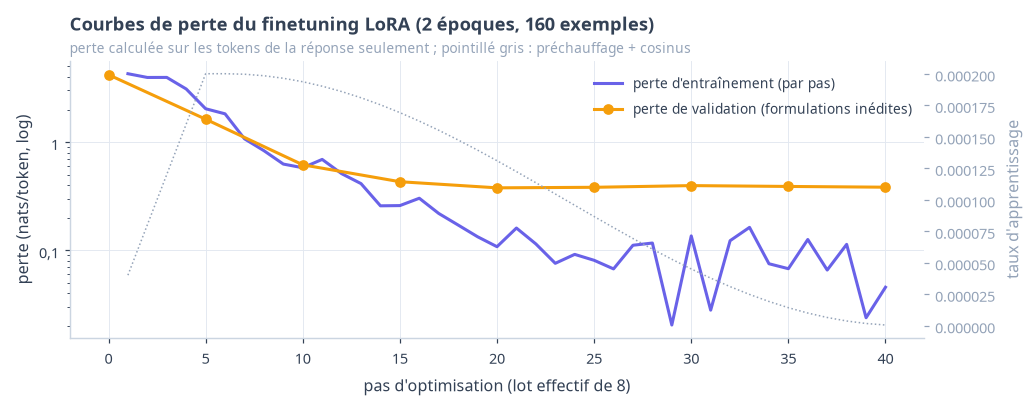

In [12]:
fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.plot(hist.step, hist.loss, color=INDIGO, alpha=0.85, label="perte d'entraînement (par pas)")
ax.plot(hist.val_step, hist.val_loss, "o-", color=AMBER, label="perte de validation (formulations inédites)")
ax.set_yscale("log"); c7.sci_log(ax, "y"); ax.set_xlabel("pas d'optimisation (lot effectif de 8)"); ax.set_ylabel("perte (nats/token, log)")
ax2 = ax.twinx(); ax2.plot(hist.step, hist.lr, color=GRAY, lw=1, ls=":"); ax2.set_ylabel("taux d'apprentissage", color=GRAY)
ax2.grid(False); ax2.tick_params(colors=GRAY)
ax.legend(loc="upper right", fontsize=9)
c7.title_sub(ax, "Courbes de perte du finetuning LoRA (2 époques, 160 exemples)",
             "perte calculée sur les tokens de la réponse seulement ; pointillé gris : préchauffage + cosinus")
plt.tight_layout(); plt.show()

La perte d'entraînement chute d'un facteur 50 à 100 en une quarantaine de pas : la
structure de la ligne (« Catégorie : », « | Urgence : »...) est apprise presque tout de
suite, le reste de la descente porte sur les valeurs des champs. La perte de validation
(sur des formulations jamais vues) descend aussi mais se stabilise plus haut : le
**résumé** de ces problèmes inédits ne peut pas être deviné mot pour mot. Évaluons
maintenant ce qui compte : le format et les champs.

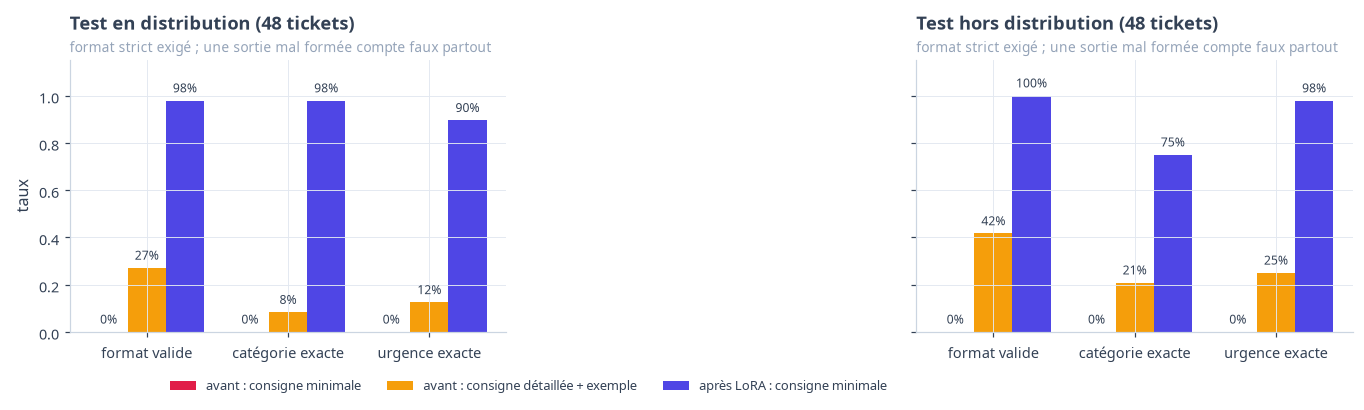

,message,attendu,sortie après LoRA
0,"Bonsoir, Il manque un article dans ma commande 33544. Simple question, aucu...",Catégorie : livraison | Urgence : basse | Résumé : article manquant,Catégorie : livraison | Urgence : basse | Résumé : absence d'article
1,"Salut, Je voudrais changer la carte bancaire de mon abonnement. Merci de me...",Catégorie : facturation | Urgence : moyenne | Résumé : changement de moyen de paiement,Catégorie : compte | Urgence : moyenne | Résumé : carte bancaire compteaires
2,"Bonjour, Le bouton de téléchargement des factures ne fait rien. Quand vous ...",Catégorie : technique | Urgence : basse | Résumé : bouton inactif,Catégorie : technique | Urgence : basse | Résumé : bouton non activé
3,"Madame, Monsieur, Je voudrais fusionner mes deux comptes. Je suis bloqué de...",Catégorie : compte | Urgence : haute | Résumé : fusion de comptes,Catégorie : compte | Urgence : haute | Résumé : fusionner des comptes
4,"Salut, Il manque un article dans ma commande 48936. Ce n'est pas grave, c'e...",Catégorie : livraison | Urgence : basse | Résumé : article manquant,Catégorie : livraison | Urgence : basse | Résumé : article manquant


In [13]:
for split, ts in [("en distribution", test_in), ("hors distribution", test_out)]:
    outs = c7.generate_batch(pmodel, tok, P(ts), 40)
    scores[("après LoRA : consigne minimale", split)] = c7.score_tickets(outs, ts)
    if split == "hors distribution":
        outs_out = outs
sc = pd.DataFrame(scores).T
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9), sharey=True)
for ax, split in zip(axes, ["en distribution", "hors distribution"]):
    sub = sc.xs(split, level=1)
    xk = np.arange(3)
    for j, (lab, col) in enumerate(zip(sub.index, [ROSE, AMBER, INDIGO])):
        ax.bar(xk + (j - 1) * 0.27, sub.loc[lab], 0.27, color=col, label=lab)
    annotate_bars(ax, "{:.0%}", fontsize=8)
    ax.set_xticks(xk, sub.columns); ax.set_ylim(0, 1.15)
    c7.title_sub(ax, f"Test {split} (48 tickets)", "format strict exigé ; une sortie mal formée compte faux partout")
axes[0].set_ylabel("taux")
axes[0].legend(fontsize=8.5, ncol=3, loc="upper center", bbox_to_anchor=(1.05, -0.12))
plt.tight_layout(); plt.show()
pd.DataFrame({"message": [t.message[:75] + "..." for t in test_out[:5]], "attendu": [t.cible for t in test_out[:5]],
              "sortie après LoRA": outs_out[:5]})

Après quelques secondes d'entraînement, le format est respecté sur la quasi-totalité des
tickets, y compris pour des formulations inédites, avec une consigne qui ne décrit même
pas le format. La catégorie et l'urgence sont en général justes ; les erreurs restantes
(à vérifier dans le tableau) portent surtout sur la catégorie des formulations nouvelles,
et les résumés inventés pour ces cas sont plausibles sans être ceux de la référence.
C'est l'illustration de la formule du cours 1 : le finetuning apprend la **forme**.

**Les effets de bord.** Le finetuning a-t-il abîmé le reste ? `peft` permet de désactiver
l'adaptateur sans recharger le modèle : comparons sur des questions sans rapport avec la
tâche.

In [14]:
qs = ["Quelle est la capitale de l'Italie ?", "Donne une idée de dessert en une phrase.",
      "Traduis « good morning » en français."]
pr = [tok.apply_chat_template([{"role": "user", "content": q}], tokenize=False, add_generation_prompt=True) for q in qs]
after = c7.generate_batch(pmodel, tok, pr, 30)
with pmodel.disable_adapter():
    before = c7.generate_batch(pmodel, tok, pr, 30)
pd.DataFrame({"question": qs, "adaptateur désactivé": [b[:80] for b in before], "adaptateur LoRA actif": [a[:80] for a in after]})

,question,adaptateur désactivé,adaptateur LoRA actif
0,Quelle est la capitale de l'Italie ?,La capitale de l'Italie est Rome.\n\nRome est le plus grand et le plus ancien des,La capitale de l'Italie est Rome.
1,Donne une idée de dessert en une phrase.,"Un dessert qui pourrait être très apprécié est le ""Chiffon d'Or"", un délicieux m",dessert : crème brûlée
2,Traduis « good morning » en français.,"""Good morning"" se traduit en français par ""Bonjour"".","Traduction : ""bonjour"""


Selon les questions, le modèle finetuné répond normalement ou se met à produire des lignes
`Catégorie : ... | Urgence : ...` hors de propos (comparez les deux colonnes) : avec 160
exemples tous du même type, il a appris que **tout** message utilisateur appelle ce format.
C'est la dégradation « ailleurs » décrite dans la section *Reasons Not to Finetune*. Les
remèdes : mélanger des exemples d'autres tâches, utiliser une consigne déclencheuse
distinctive, ou, avantage propre à LoRA, **n'activer l'adaptateur que pour cette tâche**.

> **À retenir.** Un finetuning LoRA de quelques secondes sur 160 exemples suffit à
> imposer un format qu'un prompt détaillé n'obtenait qu'en partie. Surveillez les effets de
> bord sur les autres usages du modèle : un adaptateur est spécialisé.

## 7. Servir des adaptateurs LoRA (section *Serving LoRA adapters*)

Deux options : **fusionner** $BA$ dans $W$ avant de servir (aucune latence en plus, mais
un modèle complet par tâche), ou **garder séparés** $W$ et $(A, B)$ (un léger surcoût de
calcul, mais un seul modèle de base partagé). Le livre chiffre l'enjeu du stockage : pour
100 clients, une matrice $4096 \times 4096$ (16,8 M paramètres) et $r = 8$ :

- fusion : $100 \times 16{,}8$ M $= 1{,}68$ Md paramètres ;
- séparés : $16{,}8$ M $+ 100 \times 65\,536 \approx 23{,}3$ M paramètres.

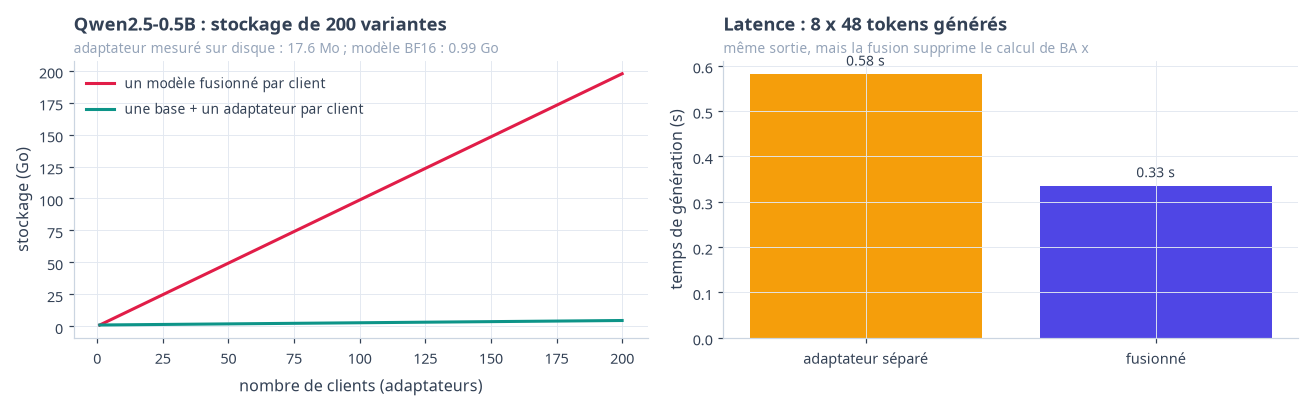

sorties identiques avant/après fusion : 7 sur 8


In [15]:
with tempfile.TemporaryDirectory() as tmp:
    pmodel.save_pretrained(tmp)
    size_adapter = sum(os.path.getsize(os.path.join(tmp, f)) for f in os.listdir(tmp))
n_clients = np.arange(1, 201)
base_bytes = N_total * 2
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(n_clients, n_clients * base_bytes / GB, color=ROSE, label="un modèle fusionné par client")
axes[0].plot(n_clients, (base_bytes + n_clients * size_adapter) / GB, color=TEAL, label="une base + un adaptateur par client")
axes[0].set_xlabel("nombre de clients (adaptateurs)"); axes[0].set_ylabel("stockage (Go)"); axes[0].legend(fontsize=9)
c7.title_sub(axes[0], "Qwen2.5-0.5B : stockage de 200 variantes",
             f"adaptateur mesuré sur disque : {size_adapter / 1e6:.1f} Mo ; modèle BF16 : {base_bytes / GB:.2f} Go")

# latence : adaptateur séparé contre fusionné (génération de 48 tokens, lot de 8)
prompts_lat = P(test_in[:8])


def gen_time(m_):
    torch.cuda.synchronize(); t = time.time()
    tok.padding_side = "left"
    enc = tok(prompts_lat, return_tensors="pt", padding=True, add_special_tokens=False).to("cuda")
    with torch.no_grad():
        m_.generate(**enc, max_new_tokens=48, min_new_tokens=48, do_sample=False, pad_token_id=tok.pad_token_id)
    torch.cuda.synchronize(); tok.padding_side = "right"
    return time.time() - t


gen_time(pmodel)
t_sep = np.median([gen_time(pmodel) for _ in range(3)])
merged_model = pmodel.merge_and_unload()
t_mer = np.median([gen_time(merged_model) for _ in range(3)])
outs_merged = c7.generate_batch(merged_model, tok, P(test_out[:8]), 40)
axes[1].bar(["adaptateur séparé", "fusionné"], [t_sep, t_mer], color=[AMBER, INDIGO])
annotate_bars(axes[1], "{:.2f} s"); axes[1].set_ylabel("temps de génération (s)")
c7.title_sub(axes[1], "Latence : 8 x 48 tokens générés", "même sortie, mais la fusion supprime le calcul de BA x")
plt.tight_layout(); plt.show()
n_same = sum(a == b for a, b in zip(outs_merged, outs_out[:8]))
print(f"sorties identiques avant/après fusion : {n_same} sur 8")

La fusion produit les mêmes sorties dans la grande majorité des cas ; les rares
différences viennent des arrondis : en BF16, $(W + BA)x$ arrondi une fois n'est pas
exactement $Wx + BAx$ arrondi deux fois, et un écart minime peut faire basculer le choix
glouton d'un token. La fusion supprime aussi le surcoût de l'adaptateur séparé, ici une part notable du temps car le modèle est petit et la LoRA
touche les sept matrices de chaque bloc. À l'inverse, garder les adaptateurs séparés
permet le **service multi-LoRA** : un seul modèle de base en mémoire, et l'on change de
client en chargeant quelques mégaoctets au lieu d'un modèle complet. Apple sert ainsi de
multiples adaptateurs sur un même modèle de 3 B embarqué dans l'iPhone, et les
adaptateurs se partagent comme des modèles (Hugging Face, AdapterHub).

Le revers de LoRA, selon le livre : une qualité généralement un peu en deçà du finetuning
complet, et une mise en œuvre qui demande de connaître l'architecture (géré par les
frameworks pour les modèles populaires).

> **À retenir.** Un seul adaptateur : fusionnez (latence nulle). Beaucoup d'adaptateurs
> sur une même base : gardez-les séparés (stockage et changement de tâche quasi gratuits).

## 8. QLoRA : LoRA sur une base quantifiée en 4 bits (section *Quantized LoRA*)

Réduire encore le nombre de paramètres LoRA ne sert presque à rien : le tableau 7-6 du
livre montre que l'adaptateur pèse des mégaoctets quand les poids pèsent des dizaines de
gigaoctets. Le levier restant est la **quantification de la base gelée**. QLoRA
(Dettmers et al., 2023) stocke les poids du modèle en **NF4** (4 bits, cours 2), les
**déquantifie à la volée** en BF16 pour les passes avant et arrière, et n'entraîne que des
adaptateurs LoRA en 16 bits. S'y ajoutent des optimiseurs « paginés » qui débordent sur la
mémoire du CPU en cas de pic. Résultat : finetuner un modèle de 65 B sur un seul GPU de
48 Go.

,poids du modèle (16 bits),"paramètres LoRA (r=2, q et k)",mémoire de l'adaptateur (16 bits)
Llama 2 (13B),26 Go,"3,28 M","6,55 Mo"
GPT-3 (175B),350 Go,"18,87 M","37,7 Mo"


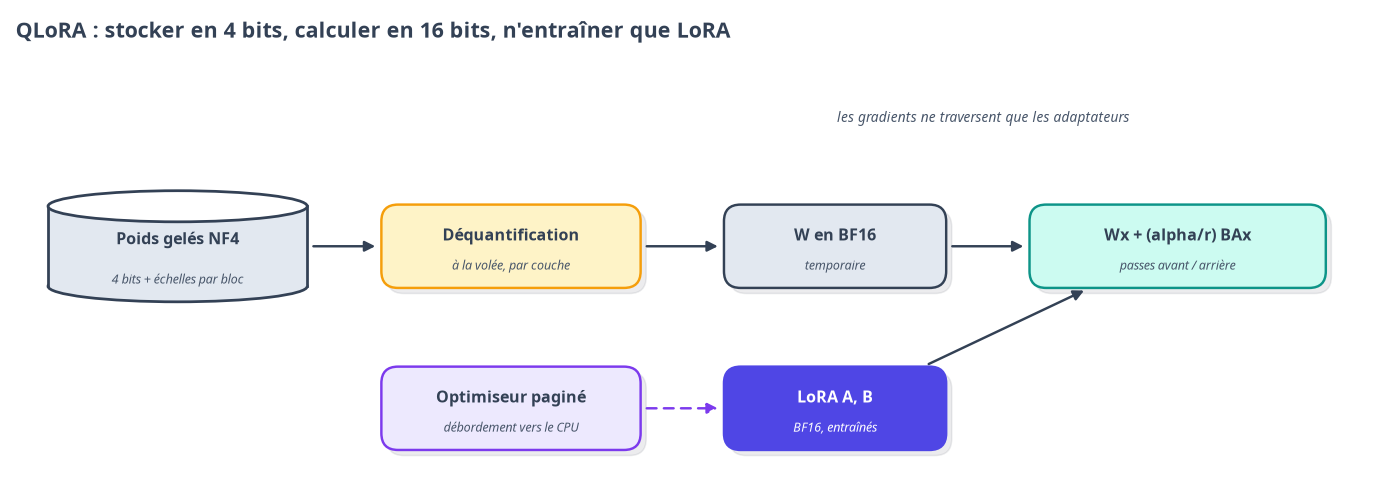

In [16]:
t76 = pd.DataFrame({"poids du modèle (16 bits)": ["26 Go", "350 Go"],
                    "paramètres LoRA (r=2, q et k)": ["3,28 M", "18,87 M"],
                    "mémoire de l'adaptateur (16 bits)": ["6,55 Mo", "37,7 Mo"]}, index=["Llama 2 (13B)", "GPT-3 (175B)"])
display(t76)

d = Diagram(14.6, 4.6, title="QLoRA : stocker en 4 bits, calculer en 16 bits, n'entraîner que LoRA")
d.box("w4", 1.8, 2.6, "Poids gelés NF4", sub="4 bits + échelles par bloc", color=SLATE, kind="db", w=2.8, h=1.2)
d.box("deq", 5.4, 2.6, "Déquantification", sub="à la volée, par couche", color=AMBER, w=2.8)
d.box("w16", 8.9, 2.6, "W en BF16", sub="temporaire", color=SLATE, w=2.4)
d.box("lora", 8.9, 0.85, "LoRA A, B", sub="BF16, entraînés", color=INDIGO, w=2.4, filled=True)
d.box("out", 12.6, 2.6, "Wx + (alpha/r) BAx", sub="passes avant / arrière", color=TEAL, w=3.2)
d.arrow("w4", "deq"); d.arrow("deq", "w16"); d.arrow("w16", "out"); d.arrow("lora", "out")
d.box("pg", 5.4, 0.85, "Optimiseur paginé", sub="débordement vers le CPU", color=VIOLET, w=2.8)
d.arrow("pg", "lora", style="dashed", color=VIOLET)
d.note(10.5, 4.0, "les gradients ne traversent que les adaptateurs", fontsize=9)
d.show()

**QLoRA en vrai.** `bitsandbytes` fonctionne sur ce GPU Blackwell : on recharge
Qwen2.5-0.5B en NF4 et l'on refait exactement le même finetuning (même LoRA, mêmes
données, mêmes hyperparamètres).

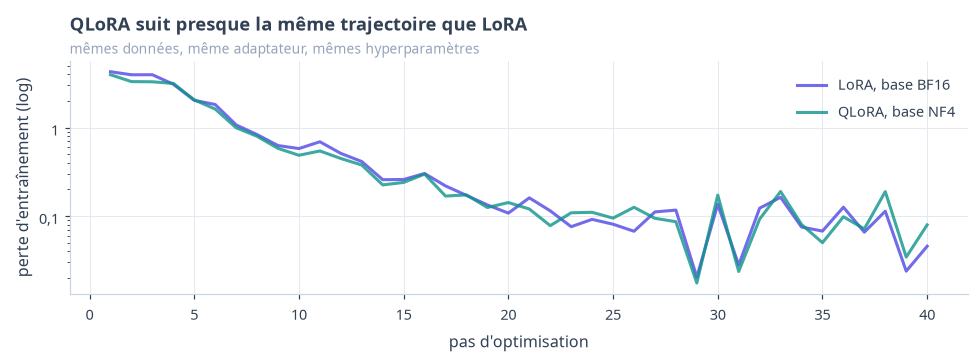

,LoRA (base BF16),QLoRA (base NF4)
poids de la base (Go),0.990,0.451
pic d'entraînement (Go),1.926,1.386
durée (s),7.638,9.742
perte de validation finale,0.384,0.461
format valide (hors distr.),1.000,1.000
catégorie exacte (hors distr.),0.750,0.750


In [17]:
del pmodel, merged_model, model; llm.free_gpu()
from transformers import BitsAndBytesConfig


def run_qlora():
    bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
                             bnb_4bit_compute_dtype=torch.bfloat16)
    tok_q, m4 = c7.load_fresh(llm.SMALL, quantization_config=bnb, device_map="cuda")
    foot = m4.get_memory_footprint()
    m4 = get_peft_model(m4, lora_cfg)
    torch.cuda.reset_peak_memory_stats()
    h = c7.train_sft(m4, train_ex, tok_q.pad_token_id, epochs=2, batch_size=2, grad_accum=4, lr=2e-4,
                     val=val_ex, eval_every=5)
    peak = torch.cuda.max_memory_allocated()
    res = {s: c7.score_tickets(c7.generate_batch(m4, tok_q, P(ts), 40), ts)
           for s, ts in [("en distribution", test_in), ("hors distribution", test_out)]}
    del m4; gc.collect(); torch.cuda.empty_cache()
    return foot, peak, h, res


foot4, peak_q, hist_q, res_q = c7.gpu_retry(run_qlora)
c7.log_vram("nb3 qlora")
comp = pd.DataFrame({
    "LoRA (base BF16)": {"poids de la base (Go)": 0.99, "pic d'entraînement (Go)": peak_lora / GB,
                         "durée (s)": hist.seconds, "perte de validation finale": hist.val_loss[-1],
                         "format valide (hors distr.)": scores[("après LoRA : consigne minimale", "hors distribution")]["format valide"],
                         "catégorie exacte (hors distr.)": scores[("après LoRA : consigne minimale", "hors distribution")]["catégorie exacte"]},
    "QLoRA (base NF4)": {"poids de la base (Go)": foot4 / GB, "pic d'entraînement (Go)": peak_q / GB,
                         "durée (s)": hist_q.seconds, "perte de validation finale": hist_q.val_loss[-1],
                         "format valide (hors distr.)": res_q["hors distribution"]["format valide"],
                         "catégorie exacte (hors distr.)": res_q["hors distribution"]["catégorie exacte"]}})
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(hist.step, hist.loss, color=INDIGO, alpha=0.8, label="LoRA, base BF16")
ax.plot(hist_q.step, hist_q.loss, color=TEAL, alpha=0.8, label="QLoRA, base NF4")
ax.set_yscale("log"); c7.sci_log(ax, "y"); ax.set_xlabel("pas d'optimisation"); ax.set_ylabel("perte d'entraînement (log)"); ax.legend()
c7.title_sub(ax, "QLoRA suit presque la même trajectoire que LoRA", "mêmes données, même adaptateur, mêmes hyperparamètres")
plt.tight_layout(); plt.show()
comp.round(3)

La base NF4 occupe environ deux fois moins de place (les embeddings, 136 M paramètres
sur 494 M, restent en 16 bits) et les courbes d'entraînement sont très proches ; la qualité
finale est du même ordre. Sur un modèle aussi petit, le pic d'entraînement est dominé par
les activations et les logits, si bien que le gain total est modeste ; sur un modèle de
65 B, ce sont les 130 Go de poids BF16 ramenés à environ 35 Go qui font toute la
différence. Côté durée, le livre note que la (dé)quantification NF4 coûte du calcul et
allonge l'entraînement des grands modèles ; sur ce petit modèle et un GPU partagé, les
durées mesurées sont du même ordre (voir le tableau), d'autres coûts dominant.

Le livre rapporte les résultats de la famille **Guanaco** (Llama finetuné en QLoRA),
évaluée en mai 2023 par GPT-4 en tournoi Elo :

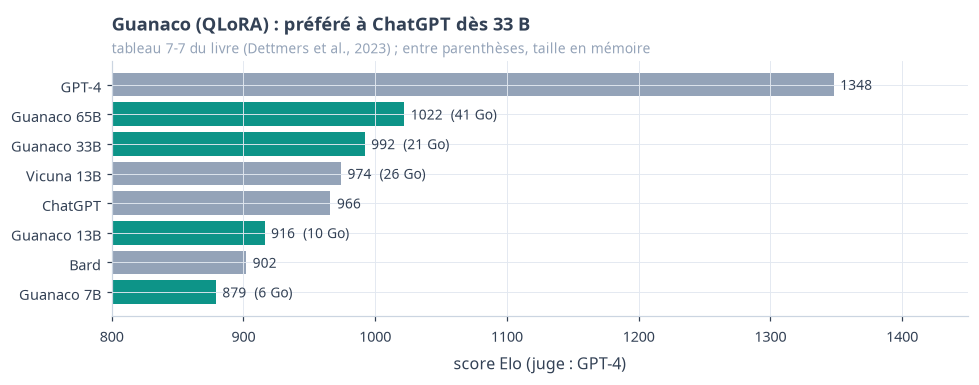

In [18]:
elo = pd.DataFrame({"Elo": [1348, 1022, 992, 974, 966, 916, 902, 879],
                    "taille": ["-", "41 Go", "21 Go", "26 Go", "-", "10 Go", "-", "6 Go"]},
                   index=["GPT-4", "Guanaco 65B", "Guanaco 33B", "Vicuna 13B", "ChatGPT", "Guanaco 13B", "Bard", "Guanaco 7B"])
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(elo.index, elo["Elo"], color=[TEAL if "Guanaco" in i else GRAY for i in elo.index])
for i, (v, t) in enumerate(zip(elo["Elo"], elo["taille"])):
    ax.text(v + 5, i, f"{v}  ({t})" if t != "-" else f"{v}", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlim(800, 1450); ax.set_xlabel("score Elo (juge : GPT-4)")
c7.title_sub(ax, "Guanaco (QLoRA) : préféré à ChatGPT dès 33 B", "tableau 7-7 du livre (Dettmers et al., 2023) ; entre parenthèses, taille en mémoire")
plt.tight_layout(); plt.show()

> **À retenir.** Une fois les paramètres entraînables réduits par LoRA, la mémoire est
> dominée par la base gelée : QLoRA la stocke en NF4 et ne paie que la déquantification à
> la volée. Qualité proche de LoRA, mémoire bien moindre, entraînement un peu plus lent.
> D'autres variantes existent (QA-LoRA, ModuLoRA, IR-QLoRA).

## Synthèse

- PEFT réduit le nombre de paramètres **entraînables** de plusieurs ordres de grandeur, et
  avec lui la mémoire des gradients et des états ; les méthodes se répartissent entre
  **adaptateurs** (LoRA en tête) et **soft prompts**.
- **LoRA** : $W' = W + \frac{\alpha}{r} BA$, $B = 0$ au départ, $r(d_{in}+d_{out})$
  paramètres par matrice ; fusionnable, donc sans latence. Elle fonctionne parce qu'adapter
  un modèle bien pré-entraîné demande peu de degrés de liberté.
- En pratique : un adaptateur de 4,4 M paramètres entraîné en quelques secondes impose un
  format strict à Qwen2.5-0.5B, mais le spécialise (effets de bord visibles).
- **Service** : fusionner pour un adaptateur, garder séparés pour du multi-LoRA.
- **QLoRA** : base en NF4 + adaptateurs 16 bits, pour finetuner de grands modèles sur un
  seul GPU.

Le cours 4 explore la **fusion de modèles** (combiner plusieurs finetunings ou
adaptateurs) et les **tactiques** d'entraînement (taux d'apprentissage, lot, époques,
poids de la perte du prompt). Le chapitre 8 traite de la constitution des données
d'entraînement.

In [19]:
llm.free_gpu()